# Grenzen der linearen Regression

Dieses Notebook ist kurz, zeigt dir aber hoffentlich die Grenzen der linearen Regression. Ein lineares Regressionsmodell kann nur **lineare** Beziehungen erkennen.
Mit dem bekannten Datensatz [Anscombe-Quartett (Anscombe's quartet)](https://en.wikipedia.org/wiki/Anscombe%27s_quartet) können wir zeigen, dass lineare Regression für sehr unterschiedliche Datensätze dieselben Ergebnisse liefern kann.

In [1]:
# Benötigte Bibliotheken importieren
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline

## Das Anscombe-Quartett

In [2]:
# Der Anscombe-Datensatz enthält 4 verschiedene Datensätze
anscombe = sns.load_dataset("anscombe")

In [3]:
# Deskriptive Statistiken für jeden Datensatz abrufen
anscombe.groupby("dataset").describe()

x                                               y            \
        count mean       std  min  25%  50%   75%   max count      mean   
dataset                                                                   
I        11.0  9.0  3.316625  4.0  6.5  9.0  11.5  14.0  11.0  7.500909   
II       11.0  9.0  3.316625  4.0  6.5  9.0  11.5  14.0  11.0  7.500909   
III      11.0  9.0  3.316625  4.0  6.5  9.0  11.5  14.0  11.0  7.500000   
IV       11.0  9.0  3.316625  8.0  8.0  8.0   8.0  19.0  11.0  7.500909   

                                                   
              std   min    25%   50%   75%    max  
dataset                                            
I        2.031568  4.26  6.315  7.58  8.57  10.84  
II       2.031657  3.10  6.695  8.14  8.95   9.26  
III      2.030424  5.39  6.250  7.11  7.98  12.74  
IV       2.030579  5.25  6.170  7.04  8.19  12.50

Wie du in der Tabelle oben siehst, haben alle vier Datensätze sehr ähnliche deskriptive Statistiken. Würden wir nur auf diese Zusammenfassung schauen, könnten wir fälschlicherweise annehmen, dass die Datensätze auch ziemlich ähnlich aussehen.
Berechnen wir jetzt einige zusammenfassende Statistiken, um die Daten mit ihren Regressionsgeraden zu plotten.
Ein einfacher Weg, eine lineare Regression nach der Methode der kleinsten Quadrate (linear least-squares regression) zu berechnen und die interessanten Statistiken zurückzubekommen, ist die Funktion `.linregress()` aus dem Modul `scipy.stats`, denn `LinearRegression` aus sklearn liefert weder p-Werte noch Standardfehler.

In [4]:
# Funktion definieren, die linregress aus dem stats-Modul nutzt,
# um für jeden Datensatz ein lineares Regressionsmodell zu bauen
# Gibt zusammenfassende Statistiken zurück
def get_summarystats(dataset):
    """ Return the slope, intercept, r_value, p_value, and std_err 
    for a linear regression model fitted to the specified dataset.

    Args:
        dataset : str
            The name of the dataset to fit the linear regression model to.

    Returns:
        slope : float
            The slope of the fitted line.
        intercept : float
            The intercept of the fitted line.
        r_value : float
            The Pearson correlation coefficient. The square of rvalue is equal to the coefficient of determination.
        p_value : float
            The two-sided p-value for a hypothesis test whose null hypothesis is that the slope is zero.
        std_err : float
            The standard error of the estimated slope.
    """
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        x=anscombe[anscombe.dataset == dataset].x,
        y=anscombe[anscombe.dataset == dataset].y,
    )

    return slope, intercept, r_value, p_value, std_err

In [5]:
# Zusammenfassende Statistiken für jeden Datensatz abrufen
results = []
for dataset in "I II III IV".split():
    slope, intercept, r_value, p_value, std_err = get_summarystats(dataset)
    results.append([slope, intercept, r_value])

print("[slope, intercept, r_value] for each dataset")
results

[slope, intercept, r_value] for each dataset


[[np.float64(0.5000909090909091),
  np.float64(3.0000909090909103),
  np.float64(0.8164205163448399)],
 [np.float64(0.5000000000000001),
  np.float64(3.000909090909089),
  np.float64(0.816236506000243)],
 [np.float64(0.4997272727272729),
  np.float64(3.002454545454544),
  np.float64(0.8162867394895984)],
 [np.float64(0.4999090909090909),
  np.float64(3.0017272727272726),
  np.float64(0.8165214368885028)]]

Auch die Parameter der linearen Regression sind fast identisch. Die Datensätze sehen aber deutlich unterschiedlich aus, wenn wir sie mit ihren Regressionsgeraden plotten.

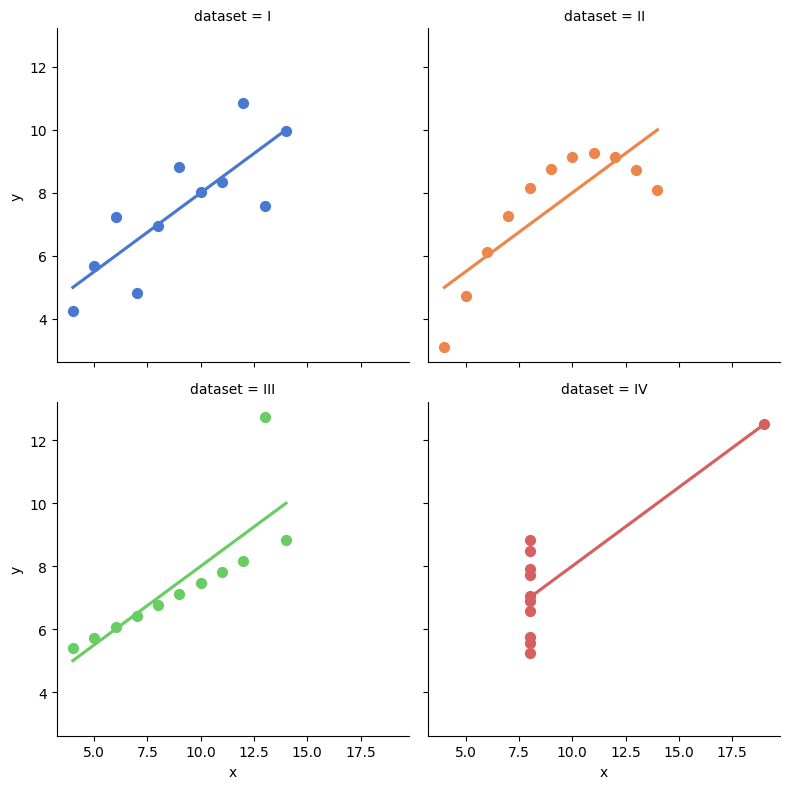

In [6]:
# Ergebnisse einer linearen Regression innerhalb jedes Datensatzes anzeigen
sns.lmplot(
    x="x",
    y="y",
    col="dataset",
    hue="dataset",
    data=anscombe,
    col_wrap=2,
    ci=None,
    palette="muted",
    height=4,
    scatter_kws={"s": 50, "alpha": 1},
);

Die angepassten Geraden sind im Grunde identisch, obwohl wir völlig unterschiedliche Daten haben.
In diesen Fällen ist absichtlich offensichtlich, dass das Modell Probleme hat, Geraden an die Datensätze II, III und IV anzupassen. Normalerweise musst du dir den Plot der Residuen ansehen, um solche Fehler zu erkennen.

## Residuenplots (Residual Plots)



In einem echten Data-Science-Projekt reicht es nicht, die Qualität deines Modells in einem einzigen Wert zusammenzufassen (wie R-Quadrat, RMSE ...). Du musst tiefer graben und herausfinden, ob die Fehler bestimmten Mustern folgen.
Ein gängiger Weg, das zu analysieren, sind sogenannte **Residuenplots (Residual Plots)**. Diese Plots zeigen, wie der Name schon sagt, die Verteilung der Residuen (residuals) deines Modells. Sie sind ein wesentlicher Teil jeder Fehleranalyse bei Regressionsproblemen!

Mit der Funktion unten können wir für jeden Datensatz Residuenplots erstellen.

In [7]:
# Funktion definieren, die Residuen berechnet und plottet
def get_residuals(dataset, color):
    # wahre y-Werte speichern
    obs_values = anscombe[anscombe.dataset == dataset].y
    # vorhergesagte y-Werte speichern
    pred_values = (
        get_summarystats(dataset)[0] * anscombe[anscombe.dataset == dataset].x
        + get_summarystats(dataset)[1]
    )
    # Residuen berechnen
    residuals = obs_values - pred_values
    # Residuen plotten
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(anscombe[anscombe.dataset == dataset].x, residuals, color=color)
    ax.set_ylabel("Residuals")
    ax.set_xlabel("x")
    fig.suptitle("Residual Scatter Plot")
    plt.show()

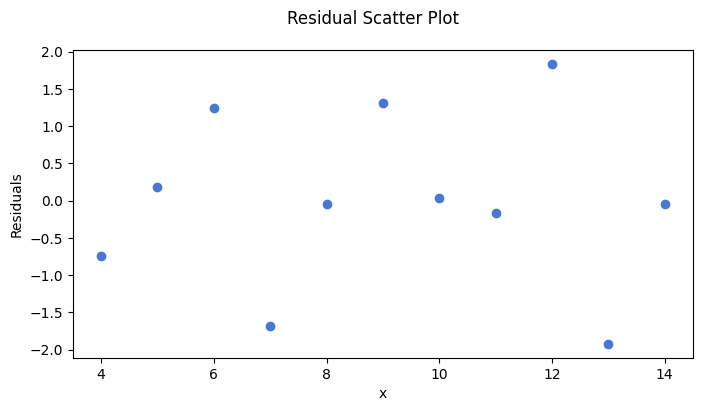

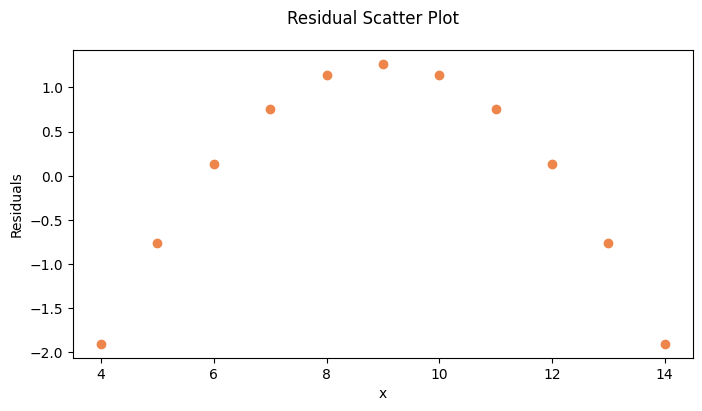

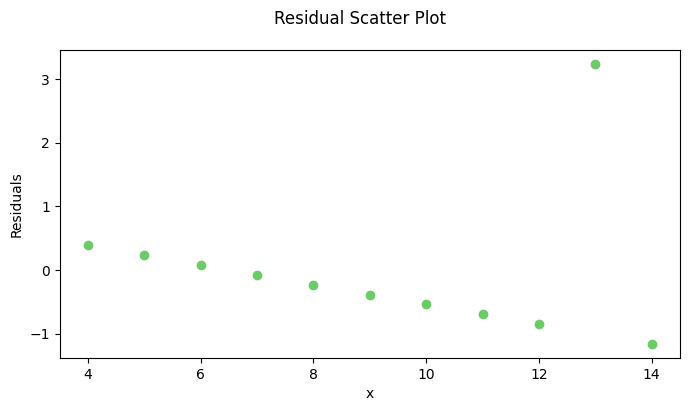

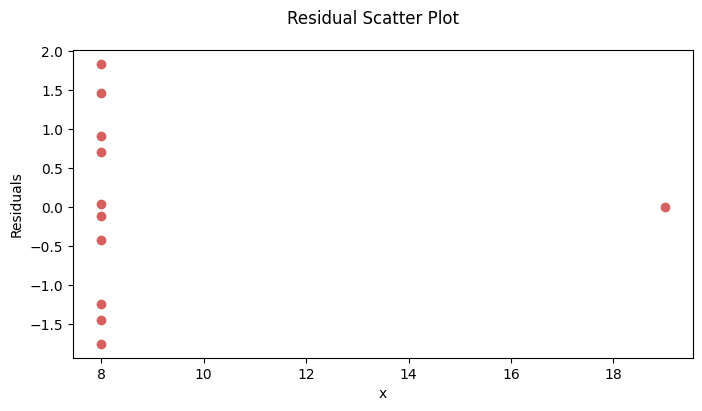

In [8]:
# Dieselbe Farbpalette wie oben festlegen
color = sns.color_palette("muted")

# Die definierte Funktion nutzen, um die Residuen aller Datensätze zu plotten
for dataset, c in zip("I II III IV".split(), color):
    get_residuals(dataset, c)

In einem gut angepassten Modell sind die Residuen zufällig verteilt.  In unserem Fall gilt das nur für Datensatz I. Bei eher schlecht angepassten Modellen findest du Muster in der Verteilung der Residuen, wie wir es bei den Datensätzen II, III und IV sehen. Diese Muster zeigen uns, dass unserem Modell zusätzliche erklärende Faktoren fehlen.  




### Weiterführende Literatur


Wenn du irgendwann mehr über Residuen und Residuenplots lernen willst, kannst du mit diesen (englischsprachigen) Artikeln anfangen:

* [Was sind Residuen in der Statistik?](https://www.statology.org/residuals/)
* [Wie nutzt man Residuenplots zur Validierung von Regressionsmodellen?](https://medium.com/data-science/how-to-use-residual-plots-for-regression-model-validation-c3c70e8ab378)
* [Residuenplots interpretieren, um deine Regression zu verbessern](https://www.qualtrics.com/support/stats-iq/analyses/regression-guides/interpreting-residual-plots-improve-regression/)
